[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-1/blob/main/notebooks/ch08_LabCh08_Optimizers_And_Learning_Rate.ipynb)

**The Why Book of Deep Learning, Part 1** by Dr. Philemon Paul Daniel

**Chapter 8: Optimizers and the Learning Rate** (Part II: Making It Learn).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-1/read.html?ch=8](https://www.micyaai.com/books/why-deep-learning-1/read.html?ch=8)
* The simplified video course for kids that this book grew from: [aikids.guru](https://www.aikids.guru)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)

Tested with TensorFlow 2.21 and Keras 3.14. In Colab: *Runtime > Run all*. A GPU runtime makes the bigger
models faster but none of them needs one.

---


# Lab Ch08 - Optimizers and the Learning Rate
## Same network, same data, same starting weights: only the way we step changes

This lab goes with **Chapter 8** of *The Why Book of Deep Learning*.

In Lab 02 you trained the network `784 -> 128 -> 64 -> 10` on MNIST with the line
`optimizer='adam'` and never looked at it again. In this lab that one line is the whole subject.

### What you will be able to do afterwards

| Skill | Where |
|---|---|
| Work out how many weight updates a training run performs | Step 4 |
| Say what a learning rate that is too small, right, or too large looks like | Steps 5 and 10 |
| Write SGD, momentum and Adam yourself in a few lines of NumPy | Step 6 |
| Compare SGD, SGD + momentum, RMSprop and Adam **fairly** | Steps 7 to 10 |
| Run a learning-rate range test | Step 11 |
| Explain what batch size does to noise, speed and the best learning rate | Steps 12 and 13 |
| Add a warm-up + cosine schedule | Step 14 |

### The rule of this lab: predict, then run

Every step asks you to **write down a prediction before you run the cell**. A wrong prediction
that you then understand teaches more than a right answer you only read.

> **Runtime:** a laptop CPU is enough. The training takes a minute or two, plus the time to import TensorFlow.
> To keep it that fast we train on **10,000** of the 60,000 MNIST images and validate on 2,000 others,
> for only a few epochs per run. For a real run use all 60,000 images and 20 to 30 epochs:
> the ranking you see here stays the same, the accuracies all rise.

---
# Part A - Setting up a fair race

---
## Step 1 - Imports and one seed

In [1]:
import math
import time
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)          # same numbers on every run

print("TensorFlow:", tf.__version__)
print("Keras     :", keras.__version__)

TensorFlow: 2.21.0
Keras     : 3.14.1


---
## Step 2 - Load a small slice of MNIST

Same preparation as Lab 02: scale the pixels to `[0, 1]` and flatten each `28 x 28` image into
a row of 784 numbers.

> **Predict:** what are the shapes of `x_train` and `x_val` after this cell?

In [2]:
(x_all, y_all), _ = keras.datasets.mnist.load_data()

N_TRAIN, N_VAL = 10_000, 2_000
x_train = x_all[:N_TRAIN].reshape(N_TRAIN, 784).astype("float32") / 255.0
y_train = y_all[:N_TRAIN]
x_val = x_all[N_TRAIN:N_TRAIN + N_VAL].reshape(N_VAL, 784).astype("float32") / 255.0
y_val = y_all[N_TRAIN:N_TRAIN + N_VAL]

print("x_train:", x_train.shape, " y_train:", y_train.shape)
print("x_val  :", x_val.shape, "  y_val  :", y_val.shape)
print("pixel range:", x_train.min(), "to", x_train.max())

x_train: (10000, 784)  y_train: (10000,)
x_val  : (2000, 784)   y_val  : (2000,)
pixel range: 0.0 to 1.0


---
## Step 3 - The network from Chapter 4, and its starting weights

`784 -> 128 -> 64 -> 10`, ReLU in the hidden layers, softmax at the end.

Lab 02 also had two `Dropout(0.2)` layers. We leave them out here: dropout adds its own random
noise to the loss curve, and today we want every wobble in a curve to come from the optimiser.
(Dropout has no weights, so the parameter count is the same.)

> **Predict:** the parameter count, by hand. Dense layer = inputs x units + units.

For a fair race every run must start from **the same** random weights. We build one model,
keep a copy of its weights, and load that copy into every new model.

In [3]:
def build_model():
    return keras.Sequential([
        layers.Input(shape=(784,)),
        layers.Dense(128, activation="relu"),
        layers.Dense(64, activation="relu"),
        layers.Dense(10, activation="softmax"),
    ])

reference = build_model()
START_WEIGHTS = reference.get_weights()

by_hand = (784 * 128 + 128) + (128 * 64 + 64) + (64 * 10 + 10)
print("layer by layer:", 784 * 128 + 128, "+", 128 * 64 + 64, "+", 64 * 10 + 10)
print("by hand :", by_hand)
print("by Keras:", reference.count_params())
assert reference.count_params() == by_hand == 109_386

loss0, acc0 = None, None
reference.compile(loss="sparse_categorical_crossentropy", metrics=["accuracy"])
loss0, acc0 = reference.evaluate(x_val, y_val, verbose=0)
print(f"\nbefore any training: val loss {loss0:.3f} (ln 10 = {math.log(10):.3f}), val accuracy {acc0:.3f}")

layer by layer: 100480 + 8256 + 650
by hand : 109386
by Keras: 109386



before any training: val loss 2.354 (ln 10 = 2.303), val accuracy 0.102


### Why we see this

109,386 knobs. An untrained 10-class network should guess, so its loss should be near
`ln(10) = 2.303` and its accuracy near 10%. If your starting loss is far from that, something is
wrong before the optimiser has done anything. Every optimiser below starts from exactly this point.

---
## Step 4 - Epoch arithmetic

An optimiser does not count in epochs. It counts in **steps**: one step = one mini-batch =
one update of all 109,386 weights.

`steps per epoch = ceil(examples / batch size)` and `total steps = steps per epoch x epochs`

> **Predict:** with 10,000 examples, batch size 128 and 5 epochs, how many times are the weights updated?
> And with batch size 16? And with the whole set as one batch?

In [4]:
def steps(examples, batch, epochs):
    return math.ceil(examples / batch) * epochs

for batch in (16, 128, 1024, N_TRAIN):
    print(f"batch {batch:>6}: {math.ceil(N_TRAIN / batch):>4} steps per epoch, "
          f"{steps(N_TRAIN, batch, 5):>5} updates in 5 epochs")

print("\nLab 02 itself: 54,000 training images, batch 128, 30 epochs ->",
      steps(54_000, 128, 30), "updates")

batch     16:  625 steps per epoch,  3125 updates in 5 epochs
batch    128:   79 steps per epoch,   395 updates in 5 epochs
batch   1024:   10 steps per epoch,    50 updates in 5 epochs
batch  10000:    1 steps per epoch,     5 updates in 5 epochs

Lab 02 itself: 54,000 training images, batch 128, 30 epochs -> 12660 updates


### Why we see this

Same data, same number of epochs, and the number of updates differs by a factor of several hundred.
Keep this table in mind in Step 13: a big batch at an unchanged learning rate is not "worse",
it has simply been allowed far fewer steps.

---
# Part B - Optimisers by hand, on a loss you can see

---
## Step 5 - One weight, one bowl, four learning rates

Take the simplest loss there is: `loss = w * w`. Its slope at `w` is `2 * w`, so one step of
gradient descent is

`w <- w - lr * 2 * w`, which is the same as `w <- (1 - 2 * lr) * w`.

Every step multiplies `w` by the same number. That number tells you everything.

> **Predict**, for a start at `w = 2`: what happens with `lr = 0.05`, `0.45`, `0.9` and `1.1`?
> (Work out `1 - 2 * lr` for each one first.)

lr = 0.05  multiplier +0.9   w: +2.00  +1.80  +1.62  +1.46  +1.31  +1.18  +1.06  +0.96  +0.86
lr = 0.45  multiplier +0.1   w: +2.00  +0.20  +0.02  +0.00  +0.00  +0.00  +0.00  +0.00  +0.00
lr = 0.9   multiplier -0.8   w: +2.00  -1.60  +1.28  -1.02  +0.82  -0.66  +0.52  -0.42  +0.34
lr = 1.1   multiplier -1.2   w: +2.00  -2.40  +2.88  -3.46  +4.15  -4.98  +5.97  -7.17  +8.60


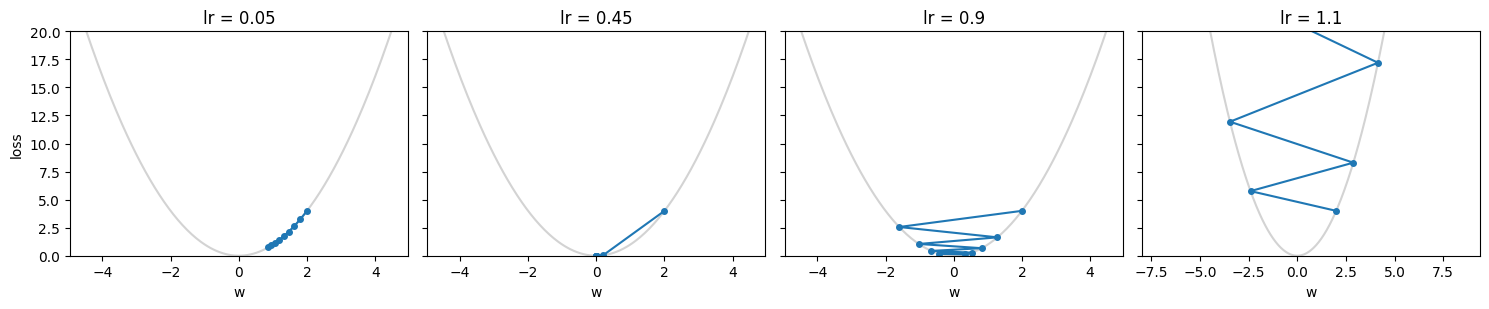

In [5]:
def descend_bowl(lr, w=2.0, n=8):
    path = [w]
    for _ in range(n):
        w = w - lr * 2 * w
        path.append(w)
    return path

for lr in (0.05, 0.45, 0.9, 1.1):
    path = descend_bowl(lr)
    print(f"lr = {lr:<4}  multiplier {1 - 2 * lr:+.1f}   w: " + "  ".join(f"{w:+.2f}" for w in path))

fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
ws = np.linspace(-4.5, 4.5, 200)
for ax, lr in zip(axes, (0.05, 0.45, 0.9, 1.1)):
    path = np.array(descend_bowl(lr))
    ax.plot(ws, ws ** 2, color="lightgrey")
    ax.plot(path, path ** 2, "o-", ms=4)
    ax.set_title(f"lr = {lr}")
    ax.set_ylim(0, 20)
    ax.set_xlabel("w")
axes[0].set_ylabel("loss")
plt.tight_layout()
plt.show()

### Why we see this

| lr | multiplier | behaviour |
|---|---|---|
| 0.05 | +0.9 | creeps: after 8 steps it is still at 43% of where it started |
| 0.45 | +0.1 | each step removes 90% of the distance: near perfect |
| 0.9 | -0.8 | jumps over the bottom every step, but each jump is smaller: it still converges |
| 1.1 | -1.2 | jumps over the bottom and lands **further away** every time: divergence |

The border is `lr = 1.0` (multiplier -1: it bounces between +2 and -2 for ever). For this bowl the
limit is `2 / curvature`, and the curvature is 2. A steeper bowl has a lower limit. A real network
is a bowl with a different steepness in every direction, and the steepest direction sets the limit
for all of them. That is the next step.

---
## Step 6 - A ravine: SGD, momentum and Adam in a few lines each

Two weights now. The loss is a long narrow valley, 100 times steeper across than along:

`loss = 0.5 * (x*x + 100 * y*y)`

The steep direction `y` allows a learning rate of at most `2 / 100 = 0.02`. We use 0.018, close
to the limit. The shallow direction `x` would like something fifty times bigger.

Below are the three update rules written out. Read them: each is two to five lines.

> **Predict:** plain gradient descent, momentum (0.9) and Adam all start at `(-4, 1)`.
> Rank them by the number of steps needed to get the loss below 0.001.

gradient descent, lr 0.018:  loss after 30 steps  2.6902   steps to reach loss < 0.001: 248
momentum 0.9,     lr 0.018:  loss after 30 steps  1.9978   steps to reach loss < 0.001: 96
Adam,             lr 0.3  :  loss after 30 steps  1.2438   steps to reach loss < 0.001: 61


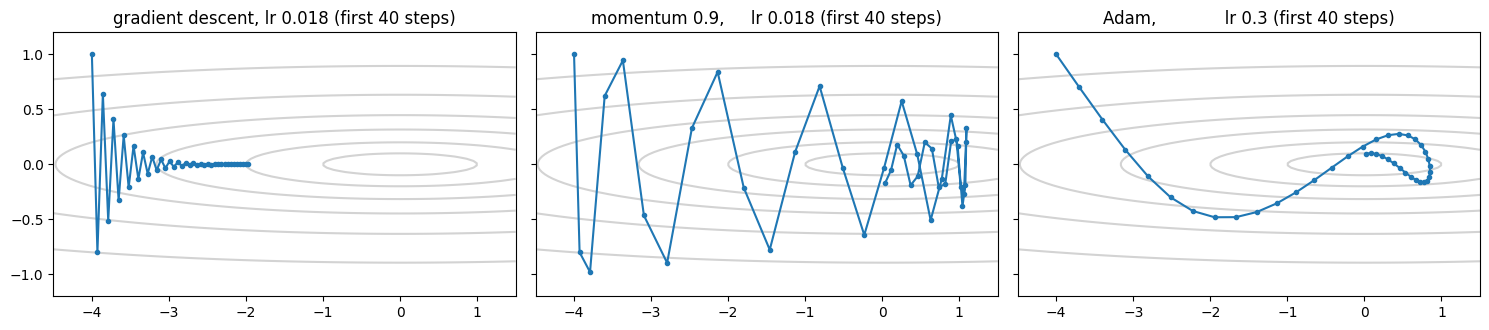

In [6]:
K = 100.0
def ravine_loss(p):
    return 0.5 * (p[0] ** 2 + K * p[1] ** 2)
def ravine_grad(p):
    return np.array([p[0], K * p[1]])

def run_gd(lr, n):
    p = np.array([-4.0, 1.0]); path = [p.copy()]
    for _ in range(n):
        p = p - lr * ravine_grad(p)                 # the whole algorithm
        path.append(p.copy())
    return np.array(path)

def run_momentum(lr, n, beta=0.9):
    p = np.array([-4.0, 1.0]); v = np.zeros(2); path = [p.copy()]
    for _ in range(n):
        v = beta * v - lr * ravine_grad(p)          # velocity: a fading memory of past gradients
        p = p + v
        path.append(p.copy())
    return np.array(path)

def run_adam(lr, n, b1=0.9, b2=0.999, eps=1e-7):
    p = np.array([-4.0, 1.0]); m = np.zeros(2); v = np.zeros(2); path = [p.copy()]
    for t in range(1, n + 1):
        g = ravine_grad(p)
        m = b1 * m + (1 - b1) * g                   # average gradient (direction)
        v = b2 * v + (1 - b2) * g * g               # average squared gradient (typical size)
        m_hat = m / (1 - b1 ** t)                   # bias correction: both averages start at zero
        v_hat = v / (1 - b2 ** t)
        p = p - lr * m_hat / (np.sqrt(v_hat) + eps)
        path.append(p.copy())
    return np.array(path)

def steps_to(path, target=1e-3):
    losses = np.array([ravine_loss(p) for p in path])
    hit = np.where(losses < target)[0]
    return int(hit[0]) if len(hit) else None

paths = {
    "gradient descent, lr 0.018": run_gd(0.018, 400),
    "momentum 0.9,     lr 0.018": run_momentum(0.018, 400),
    "Adam,             lr 0.3  ": run_adam(0.3, 400),
}
for name, path in paths.items():
    print(f"{name}:  loss after 30 steps {ravine_loss(path[30]):7.4f}   steps to reach loss < 0.001: {steps_to(path)}")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.4), sharey=True)
gx, gy = np.meshgrid(np.linspace(-4.5, 1.5, 120), np.linspace(-1.2, 1.2, 120))
for ax, (name, path) in zip(axes, paths.items()):
    ax.contour(gx, gy, 0.5 * (gx ** 2 + K * gy ** 2), levels=[0.5, 2, 5, 10, 20, 40], colors="lightgrey")
    ax.plot(path[:40, 0], path[:40, 1], "o-", ms=3)
    ax.set_title(name.strip() + " (first 40 steps)")
plt.tight_layout()
plt.show()

### Why we see this

- **Gradient descent** zig-zags across the valley (the `y` multiplier is `1 - 0.018 * 100 = -0.8`)
  while crawling along it (the `x` multiplier is `1 - 0.018 = 0.982`). The learning rate is set by the
  direction you care least about.
- **Momentum** adds up the gradients it has seen. Across the valley they alternate in sign and cancel.
  Along the valley they agree and pile up, so the ball accelerates. It overshoots the bottom and has to
  come back (a heavy ball does that), and it still arrives in well under half the steps.
- **Adam** divides each weight's step by the typical size of that weight's own gradient, so the steep
  and shallow directions both move at about `lr` per step. The valley's shape hardly matters to it.
  Look at its learning rate: 0.3 is not comparable with 0.018. **A learning rate means something
  different for each optimiser**, so never compare optimisers at one shared value.

One more honest result: make the valley less narrow (set `K = 25` and `lr = 0.07`) and plain gradient
descent **beats** momentum 0.9. Momentum is a cure for ravines, not a free speed-up.

---
# Part C - The real network

---
## Step 7 - A helper that trains one configuration

`train(...)` builds a fresh model, loads the shared starting weights, compiles it with the optimiser
you pass in, trains, and returns the Keras history plus the wall-clock time.

First run: **plain SGD at its Keras default, `learning_rate=0.01`**, batch 128, 5 epochs.

> **Predict:** the starting validation loss was about 2.3. Where will plain SGD be after 5 epochs
> (395 updates): below 0.3, around 0.6, or still above 1?

In [7]:
EPOCHS, BATCH = 5, 128
results = {}

def train(optimizer, batch_size=BATCH, epochs=EPOCHS, callbacks=None):
    model = build_model()
    model.set_weights(START_WEIGHTS)
    model.compile(optimizer=optimizer, loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    t0 = time.time()
    hist = model.fit(x_train, y_train, batch_size=batch_size, epochs=epochs,
                     validation_data=(x_val, y_val), verbose=0, callbacks=callbacks)
    h = dict(hist.history)
    h["seconds"] = time.time() - t0
    return h

def report(name, h):
    print(f"{name:<34} train loss {h['loss'][-1]:7.4f}   val loss {h['val_loss'][-1]:7.4f}   "
          f"val acc {h['val_accuracy'][-1]:.4f}   ({h['seconds']:.1f}s)")

results["SGD 0.01"] = train(keras.optimizers.SGD(learning_rate=0.01))
report("SGD 0.01", results["SGD 0.01"])
print("val loss per epoch:", [round(v, 3) for v in results["SGD 0.01"]["val_loss"]])

SGD 0.01                           train loss  0.7657   val loss  0.6790   val acc 0.8305   (1.7s)
val loss per epoch: [1.925, 1.447, 1.056, 0.818, 0.679]


### Why we see this

Nothing is broken. The loss falls every epoch, smoothly. It is just slow: 395 small steps at
0.01 do not go far. A curve that is smooth, falling and far from flat at the end is the signature
of a learning rate that is **too small** (or a run that is too short).

---
## Step 8 - Add momentum

One argument changes: `momentum=0.9`. The learning rate stays at 0.01.

With momentum 0.9, a gradient that keeps pointing the same way builds up to `1 / (1 - 0.9) = 10`
times the plain step.

> **Predict:** will the validation loss after 5 epochs be about the same as plain SGD, about half,
> or several times lower? Then guess: which plain-SGD learning rate would give a similar result?

In [8]:
results["SGD 0.01 + momentum 0.9"] = train(keras.optimizers.SGD(learning_rate=0.01, momentum=0.9))
results["SGD 0.01 + Nesterov 0.9"] = train(keras.optimizers.SGD(learning_rate=0.01, momentum=0.9, nesterov=True))
results["SGD 0.1 (no momentum)"] = train(keras.optimizers.SGD(learning_rate=0.1))
for name in ("SGD 0.01", "SGD 0.01 + momentum 0.9", "SGD 0.01 + Nesterov 0.9", "SGD 0.1 (no momentum)"):
    report(name, results[name])

SGD 0.01                           train loss  0.7657   val loss  0.6790   val acc 0.8305   (1.7s)
SGD 0.01 + momentum 0.9            train loss  0.2502   val loss  0.2742   val acc 0.9145   (1.8s)
SGD 0.01 + Nesterov 0.9            train loss  0.2466   val loss  0.2676   val acc 0.9210   (1.9s)
SGD 0.1 (no momentum)              train loss  0.2469   val loss  0.3026   val acc 0.9075   (1.9s)


### Why we see this

Momentum 0.9 at 0.01 lands close to plain SGD at **0.1**: on this easy problem most of its benefit
is the ten-times-longer effective step. That is worth knowing. When you add momentum to a run that was
already at a good learning rate, you have multiplied the effective step by ten and may need to lower
the learning rate. Nesterov's look-ahead changes little here. It matters more on harder, curvier losses.

---
## Step 9 - RMSprop and Adam at their defaults

Both adapt the step **per weight**. Both default to `learning_rate=0.001`, ten times lower than SGD's
default number, and that does *not* mean smaller steps (remember Step 6).

> **Predict:** rank all four after 5 epochs, best validation loss first:
> SGD 0.01, SGD 0.01 + momentum, RMSprop 0.001, Adam 0.001.

SGD 0.01                           train loss  0.7657   val loss  0.6790   val acc 0.8305   (1.7s)
SGD 0.01 + momentum 0.9            train loss  0.2502   val loss  0.2742   val acc 0.9145   (1.8s)
RMSprop 0.001                      train loss  0.1490   val loss  0.2075   val acc 0.9395   (2.1s)
Adam 0.001                         train loss  0.1448   val loss  0.1954   val acc 0.9400   (2.2s)


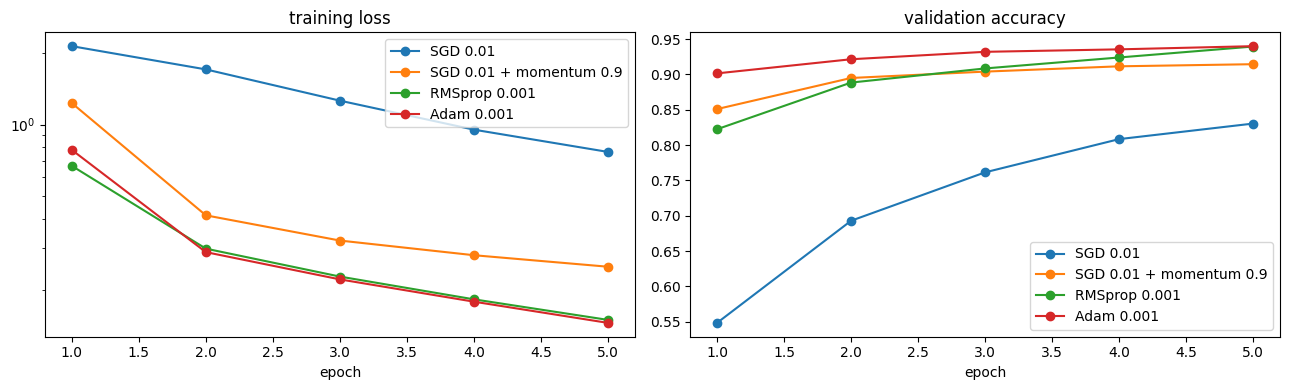

In [9]:
results["RMSprop 0.001"] = train(keras.optimizers.RMSprop(learning_rate=0.001))
results["Adam 0.001"] = train(keras.optimizers.Adam(learning_rate=0.001))

four = ["SGD 0.01", "SGD 0.01 + momentum 0.9", "RMSprop 0.001", "Adam 0.001"]
for name in four:
    report(name, results[name])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name in four:
    axes[0].plot(range(1, EPOCHS + 1), results[name]["loss"], "o-", label=name)
    axes[1].plot(range(1, EPOCHS + 1), results[name]["val_accuracy"], "o-", label=name)
axes[0].set_title("training loss"); axes[0].set_xlabel("epoch"); axes[0].set_yscale("log"); axes[0].legend()
axes[1].set_title("validation accuracy"); axes[1].set_xlabel("epoch"); axes[1].legend()
plt.tight_layout()
plt.show()

### Why we see this

At their **default** settings the adaptive optimisers win the first five epochs easily, and plain SGD
at 0.01 is last. This is the honest reason Adam is everybody's first choice: its default works on most
problems without any tuning, so the first run tells you about your model and not about your settings.

It is **not** evidence that Adam is the better optimiser. You compared four optimisers at four
arbitrary learning rates. The next step does it properly.

---
## Step 10 - Sweep the learning rate (the only fair comparison)

For each optimiser, try learning rates spaced by a factor of 10 and keep the best. Three epochs per
run keeps this quick.

> **Predict:** (a) the best learning rate for plain SGD and for Adam, to the nearest power of ten;
> (b) what the validation loss does at SGD `lr = 10` and at Adam `lr = 0.1`;
> (c) once each uses its own best rate, how far apart the four optimisers are.


SGD
   lr 0.001   val loss   2.2147   val acc 0.1925
   lr 0.01    val loss   1.0557   val acc 0.7615
   lr 0.1     val loss   0.3896   val acc 0.8855
   lr 1       val loss   0.5171   val acc 0.8635
   lr 10      val loss   2.5166   val acc 0.1120



SGD + momentum
   lr 0.0001  val loss   2.2194   val acc 0.1860
   lr 0.001   val loss   1.1195   val acc 0.7565
   lr 0.01    val loss   0.3158   val acc 0.9040
   lr 0.1     val loss   0.2190   val acc 0.9405
   lr 1       val loss   2.3305   val acc 0.0980



RMSprop
   lr 1e-05   val loss   2.1331   val acc 0.3170
   lr 0.0001  val loss   0.6639   val acc 0.8470
   lr 0.001   val loss   0.2980   val acc 0.9085
   lr 0.01    val loss   0.1942   val acc 0.9430
   lr 0.1     val loss   1.4117   val acc 0.4770



Adam
   lr 1e-05   val loss   2.1352   val acc 0.3100
   lr 0.0001  val loss   0.6348   val acc 0.8580
   lr 0.001   val loss   0.2316   val acc 0.9320
   lr 0.01    val loss   0.2092   val acc 0.9425
   lr 0.1     val loss   1.2148   val acc 0.5315

Best of each (3 epochs):
   SGD             best lr 0.1     val loss 0.3896   val acc 0.8855
   SGD + momentum  best lr 0.1     val loss 0.2190   val acc 0.9405
   RMSprop         best lr 0.01    val loss 0.1942   val acc 0.9430
   Adam            best lr 0.01    val loss 0.2092   val acc 0.9425


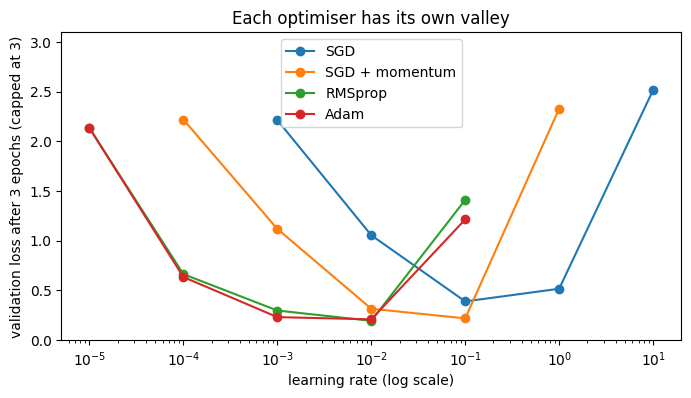

In [10]:
SWEEP = {
    "SGD":            (lambda lr: keras.optimizers.SGD(learning_rate=lr),               [1e-3, 1e-2, 1e-1, 1.0, 10.0]),
    "SGD + momentum": (lambda lr: keras.optimizers.SGD(learning_rate=lr, momentum=0.9), [1e-4, 1e-3, 1e-2, 1e-1, 1.0]),
    "RMSprop":        (lambda lr: keras.optimizers.RMSprop(learning_rate=lr),           [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]),
    "Adam":           (lambda lr: keras.optimizers.Adam(learning_rate=lr),              [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]),
}
sweep = {}
for name, (make, lrs) in SWEEP.items():
    sweep[name] = []
    for lr in lrs:
        h = train(make(lr), epochs=3)
        sweep[name].append((lr, h["val_loss"][-1], h["val_accuracy"][-1]))
    print(f"\n{name}")
    for lr, vl, va in sweep[name]:
        print(f"   lr {lr:<7g} val loss {vl:8.4f}   val acc {va:.4f}")

print("\nBest of each (3 epochs):")
for name, rows in sweep.items():
    rows_ok = [r for r in rows if np.isfinite(r[1])]
    lr, vl, va = min(rows_ok, key=lambda r: r[1])
    print(f"   {name:<15} best lr {lr:<7g} val loss {vl:.4f}   val acc {va:.4f}")

plt.figure(figsize=(8, 4))
for name, rows in sweep.items():
    plt.plot([r[0] for r in rows], [min(r[1], 3.0) if np.isfinite(r[1]) else 3.0 for r in rows], "o-", label=name)
plt.xscale("log"); plt.ylim(0, 3.1)
plt.xlabel("learning rate (log scale)"); plt.ylabel("validation loss after 3 epochs (capped at 3)")
plt.title("Each optimiser has its own valley"); plt.legend(); plt.show()

### Why we see this

- Every optimiser has a **U-shaped valley**: too small and it has not got anywhere in three epochs,
  too large and the loss is stuck near (or above) the 2.3 of pure guessing, or is `nan`.
- The valleys sit in **different places**. Plain SGD wants a rate about ten times larger than
  Adam's. Comparing them at one shared number would make one of them look terrible.
- At their own best rates, SGD + momentum, RMSprop and Adam are **close** (validation losses of about
  0.19 to 0.22 in our run). Plain SGD is still behind after only three epochs: without momentum, even its
  best steps are short. Across the sweep, the learning rate moved the result far more than the choice of
  optimiser did. That is the main lesson of the lab.
- Adam at 0.01, ten times its default, was fine on this small network. On deep networks and transformers
  the same move is a classic route to instability. Adam at 0.1 shows what that looks like here.
- Look at where the default sits in each valley. Adam's default (0.001) is at or next to its best.
  SGD's default (0.01) is a factor of ten or more too low for this network. "Adam works out of the box"
  is a statement about defaults.

---
## Step 11 - The learning-rate range test

A sweep costs one training run per value. The range test finds the useful region in **one** short run:
start with a tiny learning rate and multiply it by a constant after every batch, recording the loss
on each batch. The loss does nothing, then falls, then blows up.

We write the training step by hand for this, so that we can see the loss of every single batch.
This is all `model.fit` does inside: forward pass, loss, gradients (Chapter 7), and one call to the optimiser.

> **Predict:** for plain SGD going from `1e-4` to `10` over 200 batches, at roughly what learning rate
> does the loss start to fall quickly, and where does it blow up? (Use your Step 10 table.)

SGD   lowest smoothed loss 0.999 at lr = 0.329;  loss blows up near lr = 1.32;  a sensible choice: about 0.03 to 0.1


Adam  lowest smoothed loss 0.346 at lr = 0.0252;  loss blows up near lr = 0.153;  a sensible choice: about 0.003 to 0.008


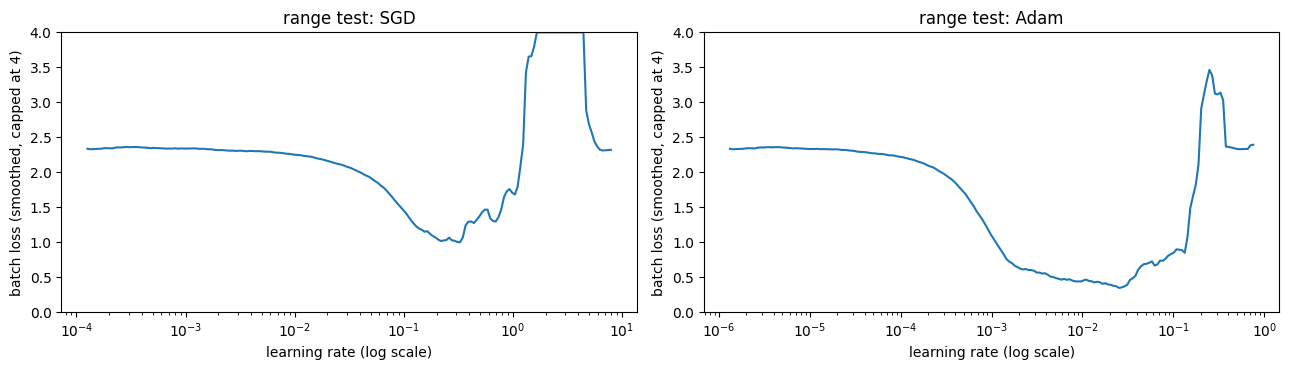

In [11]:
loss_fn = keras.losses.SparseCategoricalCrossentropy()

def make_step(model, optimizer):
    @tf.function
    def step(xb, yb):
        with tf.GradientTape() as tape:
            loss = loss_fn(yb, model(xb, training=True))
        grads = tape.gradient(loss, model.trainable_variables)        # Chapter 7: which way is downhill
        optimizer.apply_gradients(zip(grads, model.trainable_variables))   # Chapter 8: how far to go
        return loss
    return step

def batches(batch_size, n_steps, seed=0):
    rng = np.random.default_rng(seed)
    for _ in range(n_steps):
        idx = rng.integers(0, N_TRAIN, size=batch_size)
        yield x_train[idx], y_train[idx]

def range_test(make_optimizer, lr_min, lr_max, n_steps=200, batch_size=128):
    model = build_model(); model.set_weights(START_WEIGHTS)
    opt = make_optimizer(lr_min)
    step = make_step(model, opt)
    lrs = lr_min * (lr_max / lr_min) ** (np.arange(n_steps) / (n_steps - 1))
    losses = []
    for lr, (xb, yb) in zip(lrs, batches(batch_size, n_steps)):
        opt.learning_rate.assign(lr)
        losses.append(float(step(xb, yb)))
    return lrs, np.array(losses)

def smooth(v, k=9):
    v = np.where(np.isfinite(v), v, 50.0)
    return np.convolve(np.minimum(v, 50.0), np.ones(k) / k, mode="valid")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, (name, make, lo, hi) in zip(axes, [
        ("SGD", lambda lr: keras.optimizers.SGD(learning_rate=lr), 1e-4, 10.0),
        ("Adam", lambda lr: keras.optimizers.Adam(learning_rate=lr), 1e-6, 1.0)]):
    lrs, losses = range_test(make, lo, hi)
    sm = smooth(losses); sm_lrs = lrs[4:-4]
    best = sm_lrs[np.argmin(sm)]
    above = np.where((sm_lrs > best) & (sm > 2 * sm.min() + 0.5))[0]
    blow = sm_lrs[above[0]] if len(above) else float("nan")
    print(f"{name:<5} lowest smoothed loss {sm.min():.3f} at lr = {best:.3g};  loss blows up near lr = {blow:.3g};  "
          f"a sensible choice: about {best / 10:.1g} to {best / 3:.1g}")
    ax.plot(sm_lrs, np.minimum(sm, 4)); ax.set_xscale("log"); ax.set_ylim(0, 4)
    ax.set_title(f"range test: {name}"); ax.set_xlabel("learning rate (log scale)"); ax.set_ylabel("batch loss (smoothed, capped at 4)")
plt.tight_layout(); plt.show()

### Why we see this

The curve has three regions: flat (rate too small to matter), falling (the useful range), and exploding.
**Do not choose the rate at the lowest point of the curve.** By then the run is already on the edge of
blowing up, and the loss there is low partly thanks to all the steps taken before it. Choose a rate
somewhere on the steep falling part, typically three to ten times below the minimum. Compare with your
Step 10 table: 200 batches told you nearly the same thing as the ten sweep runs for these two optimisers.

---
## Step 12 - Batch size and noise

Each mini-batch gives an **estimate** of the true gradient, and so each batch loss is a noisy reading.
The noise shrinks with the square root of the batch size: four times the batch, half the noise.

We train three copies with plain SGD at 0.1 for 150 steps each, with batch sizes 8, 64 and 512, and
record the loss of every batch.

> **Predict:** (a) which curve is the most jagged; (b) roughly how much noisier batch 8 is than batch 512
> (hint: `sqrt(512 / 8)`); (c) after the same 150 **steps**, do the three reach a similar loss?

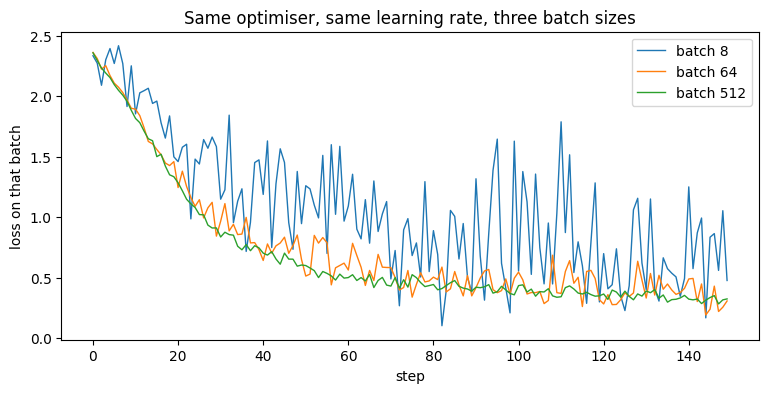

batch   8: mean loss over steps 100-149 = 0.731   spread (std) = 0.364   images seen = 1,200
batch  64: mean loss over steps 100-149 = 0.404   spread (std) = 0.112   images seen = 9,600
batch 512: mean loss over steps 100-149 = 0.359   spread (std) = 0.038   images seen = 76,800

spread of batch 8 / spread of batch 512 = 9.7   (square-root rule predicts about 8)


In [12]:
noise = {}
for bs in (8, 64, 512):
    model = build_model(); model.set_weights(START_WEIGHTS)
    step = make_step(model, keras.optimizers.SGD(learning_rate=0.1))
    noise[bs] = np.array([float(step(xb, yb)) for xb, yb in batches(bs, 150, seed=1)])

plt.figure(figsize=(9, 4))
for bs, losses in noise.items():
    plt.plot(losses, label=f"batch {bs}", lw=1)
plt.xlabel("step"); plt.ylabel("loss on that batch"); plt.title("Same optimiser, same learning rate, three batch sizes")
plt.legend(); plt.show()

for bs, losses in noise.items():
    tail = losses[100:]
    print(f"batch {bs:>3}: mean loss over steps 100-149 = {tail.mean():.3f}   spread (std) = {tail.std():.3f}   "
          f"images seen = {bs * 150:,}")
print(f"\nspread of batch 8 / spread of batch 512 = {noise[8][100:].std() / noise[512][100:].std():.1f}"
      f"   (square-root rule predicts about {math.sqrt(512 / 8):.0f})")

### Why we see this

All three head downhill, because the average direction is the same. Per step, the bigger batches end
lower, since each of their steps points more accurately, but the returns shrink fast: batch 512 sees
eight times the images of batch 64 and gains only a little. Batch 8 makes real progress on 64 times fewer
images than batch 512, which is why mini-batches exist at all: a rough direction now is worth more than
an exact direction much later. The price is the jagged curve.

A jagged training curve is therefore not a sign of a sick model. Before you worry, check the batch size,
and judge progress by the validation loss or by a smoothed curve.

---
## Step 13 - Batch size at a fixed number of epochs, and the linear scaling rule

Now the comparison people usually make: same **epochs**, different batch size. Remember Step 4:
a bigger batch means fewer updates.

We run SGD + momentum for 4 epochs at batch 16, 64, 256 and 1024, twice:
once with the learning rate fixed at 0.01, and once scaled with the batch (`0.01 x batch / 64`).

> **Predict:** (a) at fixed lr, which batch size has the best validation loss after 4 epochs, and why;
> (b) which is fastest in seconds; (c) does scaling the learning rate close the gap?

In [13]:
print(f"{'batch':>6} {'updates':>8} | {'lr':>7} {'val loss':>9} {'val acc':>8} {'sec':>5} | {'lr':>7} {'val loss':>9} {'val acc':>8}")
batch_rows = []
for bs in (16, 64, 256, 1024):
    fixed = train(keras.optimizers.SGD(learning_rate=0.01, momentum=0.9), batch_size=bs, epochs=4)
    lr_scaled = 0.01 * bs / 64
    scaled = train(keras.optimizers.SGD(learning_rate=lr_scaled, momentum=0.9), batch_size=bs, epochs=4)
    batch_rows.append((bs, fixed, lr_scaled, scaled))
    print(f"{bs:>6} {steps(N_TRAIN, bs, 4):>8} | {0.01:>7g} {fixed['val_loss'][-1]:>9.4f} {fixed['val_accuracy'][-1]:>8.4f} "
          f"{fixed['seconds']:>5.1f} | {lr_scaled:>7g} {scaled['val_loss'][-1]:>9.4f} {scaled['val_accuracy'][-1]:>8.4f}")

 batch  updates |      lr  val loss  val acc   sec |      lr  val loss  val acc


    16     2500 |    0.01    0.2165   0.9405   5.9 |  0.0025    0.2429   0.9330


    64      628 |    0.01    0.2306   0.9300   2.4 |    0.01    0.2306   0.9300


   256      160 |    0.01    0.3372   0.8995   1.5 |    0.04    0.2629   0.9150


  1024       40 |    0.01    0.9444   0.7755   1.2 |    0.16    0.2854   0.9125


### Why we see this

- **Fixed learning rate:** the small batch wins on loss, only because it took many more steps
  (2,500 against 40). It is also the slowest in seconds: many small steps make poor use of the hardware.
- **Scaled learning rate:** the big batches recover most of the gap. Each of their steps uses a cleaner
  gradient, so it can safely be longer. That is the *linear scaling rule*: multiply the batch by k,
  multiply the learning rate by about k.
- The rule is a starting point and it breaks at the extremes. Scale far enough and the learning rate
  crosses the stability limit you met in Step 5. That is why very large batches are started with a
  **warm-up** (next step).

**Changing the batch size changes the best learning rate.** If you tune one and then change the other,
you have to tune again.

---
## Step 14 - A schedule: warm-up, then cosine decay

A constant learning rate is a compromise: big enough to make progress early, small enough to settle late.
A schedule stops compromising. We compare three runs of Adam, 8 epochs each:

1. constant `0.001` (the default);
2. constant `0.004` (deliberately on the hot side);
3. **warm-up + cosine**: rise from 0 to `0.004` over the first epoch, then glide down to 0.

Keras schedules count in **steps**, not epochs: with 79 steps per epoch, 8 epochs are 632 steps.

> **Predict:** which run has the lowest training loss at the end? Which has the best validation loss?

steps per epoch: 79   total steps: 632
   step    0: lr = 0.00000
   step   39: lr = 0.00197
   step   79: lr = 0.00400
   step  316: lr = 0.00245
   step  631: lr = 0.00000



Adam constant 0.001                train loss  0.0804   val loss  0.1768   val acc 0.9490   (3.1s)
Adam constant 0.004                train loss  0.0252   val loss  0.2043   val acc 0.9530   (3.2s)
Adam warm-up + cosine, peak 0.004  train loss  0.0283   val loss  0.1516   val acc 0.9595   (3.1s)


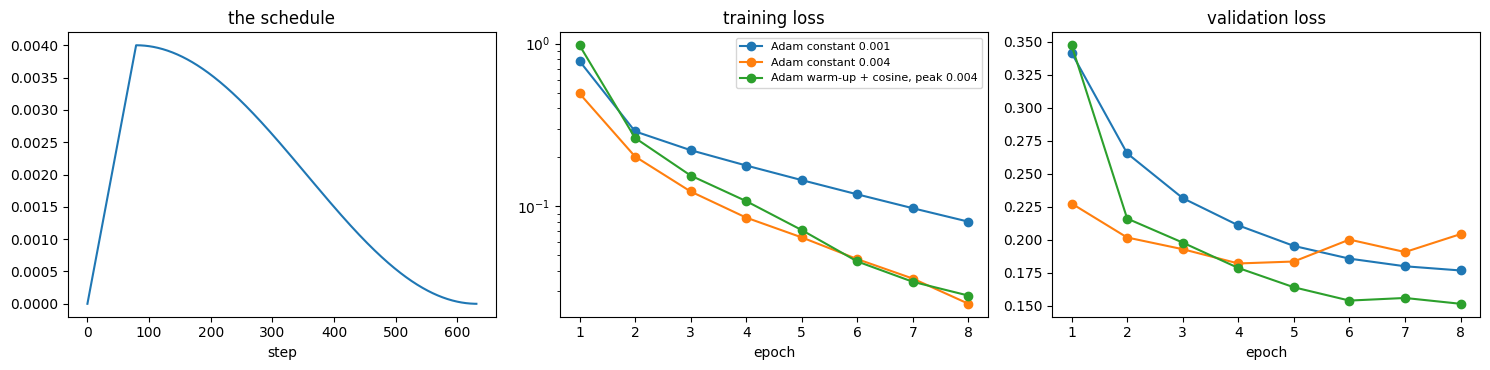

In [14]:
SCHED_EPOCHS = 8
spe = math.ceil(N_TRAIN / BATCH)                      # steps per epoch
total = spe * SCHED_EPOCHS
print("steps per epoch:", spe, "  total steps:", total)

schedule = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=0.0,          # where the warm-up starts
    warmup_target=0.004,                # the peak
    warmup_steps=spe,                   # one epoch of warm-up
    decay_steps=total - spe,            # cosine over the rest
)
for s in (0, spe // 2, spe, total // 2, total - 1):
    print(f"   step {s:>4}: lr = {float(schedule(s)):.5f}")

sched_runs = {
    "Adam constant 0.001": train(keras.optimizers.Adam(learning_rate=0.001), epochs=SCHED_EPOCHS),
    "Adam constant 0.004": train(keras.optimizers.Adam(learning_rate=0.004), epochs=SCHED_EPOCHS),
    "Adam warm-up + cosine, peak 0.004": train(keras.optimizers.Adam(learning_rate=schedule), epochs=SCHED_EPOCHS),
}
print()
for name, h in sched_runs.items():
    report(name, h)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].plot([float(schedule(s)) for s in range(total)]); axes[0].set_title("the schedule"); axes[0].set_xlabel("step")
for name, h in sched_runs.items():
    axes[1].plot(range(1, SCHED_EPOCHS + 1), h["loss"], "o-", label=name)
    axes[2].plot(range(1, SCHED_EPOCHS + 1), h["val_loss"], "o-", label=name)
axes[1].set_title("training loss"); axes[1].set_yscale("log"); axes[1].set_xlabel("epoch"); axes[1].legend(fontsize=8)
axes[2].set_title("validation loss"); axes[2].set_xlabel("epoch")
plt.tight_layout(); plt.show()

### Why we see this

Both runs that reach a peak of 0.004 end with a training loss about three times lower than the default
run. Only the scheduled one turns that into the best **validation** loss. The constant-0.004 run is still
taking large steps at the end, rattling around the floor of the valley, and its validation loss is the
worst of the three. The scheduled run takes large steps while they are useful, then shrinks them, so the
weights settle.

Two honest caveats. On this small slice of MNIST the network has begun to memorise its 10,000 training
images after a few epochs, so a lower training loss does not have to mean a lower validation loss
(Chapter 11). And these are single runs: differences of a few hundredths can move with the seed.

On a network this small, warm-up itself is not needed. It earns its place with large batches,
deep networks and transformers, where the first few hundred steps are the dangerous ones.

---
## Step 15 - Let the validation loss drive the learning rate

If you do not want to design a schedule, let a callback do it. `ReduceLROnPlateau` watches a number
(here `val_loss`) and multiplies the learning rate by `factor` whenever that number has not improved
for `patience` epochs. It counts in **epochs**, unlike the schedule above.

> **Predict:** starting Adam at `0.004`, with `factor=0.5` and `patience=1`, how many times will the
> rate be halved in 8 epochs?

In [15]:
class LrLogger(keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        self.lrs = getattr(self, "lrs", []) + [float(self.model.optimizer.learning_rate)]

logger = LrLogger()
plateau = keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1, min_lr=1e-5)
h = train(keras.optimizers.Adam(learning_rate=0.004), epochs=SCHED_EPOCHS, callbacks=[plateau, logger])
report("Adam 0.004 + ReduceLROnPlateau", h)
print("learning rate at the end of each epoch:", [round(v, 5) for v in logger.lrs])
print("validation loss per epoch             :", [round(v, 4) for v in h["val_loss"]])

Adam 0.004 + ReduceLROnPlateau     train loss  0.0150   val loss  0.1664   val acc 0.9600   (3.1s)
learning rate at the end of each epoch: [0.004, 0.004, 0.004, 0.004, 0.002, 0.002, 0.002, 0.001]
validation loss per epoch             : [0.2275, 0.2017, 0.1929, 0.1821, 0.1836, 0.1651, 0.1641, 0.1664]


### Why we see this

Each time the validation loss fails to improve, the rate is halved and the loss gets a little more room
to settle. This callback is a good default when you have no idea how long training should last. Its
weakness: it reacts to the *validation* loss, so if that stops improving because the model is
overfitting, a smaller learning rate will not help.

---
## Trials: change one thing at a time

Write your prediction in the table **before** you run each trial.

| # | Change | Predict | Observe |
|---|---|---|---|
| 1 | Step 7: `SGD(learning_rate=0.5)` | faster or unstable? | |
| 2 | Step 9: `Adam(learning_rate=0.01)` for 5 epochs | better or worse than 0.001? does the loss ever rise? | |
| 3 | Step 9: `Adam(learning_rate=1e-5)` for 5 epochs | what does the curve look like? how would you tell it from a bug? | |
| 4 | Step 8: momentum `0.99` at lr 0.01 | effective step is now 100 times: stable? | |
| 5 | Step 6: `K = 25`, `lr = 0.07` for gradient descent and momentum | who wins now? | |
| 6 | Step 9: `keras.optimizers.Adagrad(learning_rate=0.01)` | fast start? what about later epochs? | |
| 7 | Step 12: batch size 1 (150 steps) | how jagged? | |
| 8 | Step 14: `warmup_steps=0` with a peak of `0.02` | what happens in epoch 1? | |

## Exercises

1. **Epoch arithmetic.** You train on all 60,000 MNIST images with `validation_split=0.1`, batch 256,
   for 20 epochs. How many weight updates is that? Check with the `steps` function from Step 4.
2. **Fair comparison.** Add `keras.optimizers.AdamW(learning_rate=lr, weight_decay=0.004)` to the sweep
   in Step 10. Is its best learning rate the same as Adam's? Is the validation loss different after
   3 epochs? After 15?
3. **Bias correction.** In `run_adam` (Step 6) delete the two bias-correction lines and use `m` and `v`
   directly. How big is the very first step now, compared with `lr`? (Work it out by hand first:
   `0.1 / sqrt(0.001)`.)
4. **Range test on a different batch size.** Run Step 11 with `batch_size=1024`. Does the usable range of
   learning rates move? In which direction, and why?
5. **Step decay.** Replace the cosine schedule in Step 14 with
   `keras.optimizers.schedules.ExponentialDecay(0.004, decay_steps=2 * spe, decay_rate=0.5, staircase=True)`.
   Print the learning rate at the start of each epoch before you train.
6. **The full run.** Set `N_TRAIN = 54_000`, `N_VAL = 6_000`, `EPOCHS = 20` and repeat Steps 7 to 9.
   Does the ranking change? Does the gap between the optimisers grow or shrink?

## Cheat sheet

```python
keras.optimizers.SGD(learning_rate=0.01)                          # plain; default 0.01
keras.optimizers.SGD(learning_rate=0.01, momentum=0.9)            # heavy ball
keras.optimizers.SGD(learning_rate=0.01, momentum=0.9, nesterov=True)
keras.optimizers.RMSprop(learning_rate=0.001)                     # per-weight step sizes
keras.optimizers.Adam(learning_rate=0.001)                        # momentum + per-weight sizes
keras.optimizers.AdamW(learning_rate=0.001, weight_decay=0.004)   # Adam + decoupled weight decay

# a schedule goes where the number went (counted in STEPS)
sched = keras.optimizers.schedules.CosineDecay(0.0, decay_steps, warmup_target=0.004, warmup_steps=w)
keras.optimizers.Adam(learning_rate=sched)

# or let the validation loss decide (counted in EPOCHS)
keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3)
```

| You see | Think |
|---|---|
| loss falls smoothly but slowly, still falling at the end | learning rate too small, or too few steps |
| loss jumps up in the first steps, or is `nan` | learning rate too large: divide by 10 |
| loss stuck near `ln(classes)` | rate far too large (or far too small): run a range test |
| jagged training curve | small batch: normal; look at validation or smooth it |
| changed the batch size | re-tune the learning rate (start from the linear scaling rule) |
| one optimiser "beats" another | were both at their own best learning rate? |

**Tuning order:** learning rate first, then batch size (and re-check the rate), then a schedule,
then weight decay.